# 02｜位置＋RGBと、明示的な隣接領域併合

5次元の包含単体IDだけでは、画像上で同じIDが非連結になる場合があります。
`MergeConfig` を渡した場合だけ、4近傍連結成分に分離し、隣接対のWardコストで指定領域数まで併合します。
以下の尺度はRGBが0〜255のときの値です。格子分割と併合を区別して確認します。

In [1]:
import os

# 検証実行時だけ明示的に選ぶ接続です。通常実行はnanobindを使います。
if os.environ.get("PERMUTOHEDRAL_TEST_BRIDGE") == "1":
    from scripts._project import activate_test_bridge
    activate_test_bridge()

import numpy as np
from PIL import Image
from IPython.display import display
from permutohedral_segmentation import LatticeConfig, MergeConfig, segment
from permutohedral_segmentation import _native
from permutohedral_segmentation.datasets import load_example
from permutohedral_segmentation.visualization import render_labels, overlay_boundaries

backend = getattr(_native, "__test_backend__", "nanobind")
print("実行した接続方式:", backend)


実行した接続方式: ctypes-test-adapter (nanobind not validated)


直接分割: 16,350単体ID、90,755連結成分


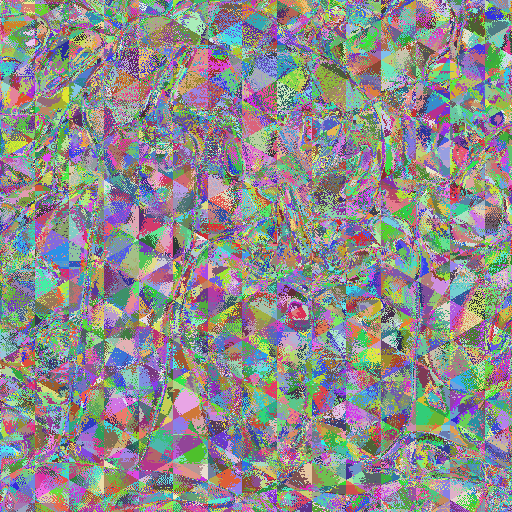

In [2]:
image = load_example("peppers")
lattice = LatticeConfig("xyrgb", spatial_scale=0.025, color_scale=0.01)
raw = segment(image, lattice=lattice)
print(f"直接分割: {raw.simplex_count:,}単体ID、{raw.component_count:,}連結成分")
display(Image.fromarray(render_labels(raw.labels)))

併合後: 300領域


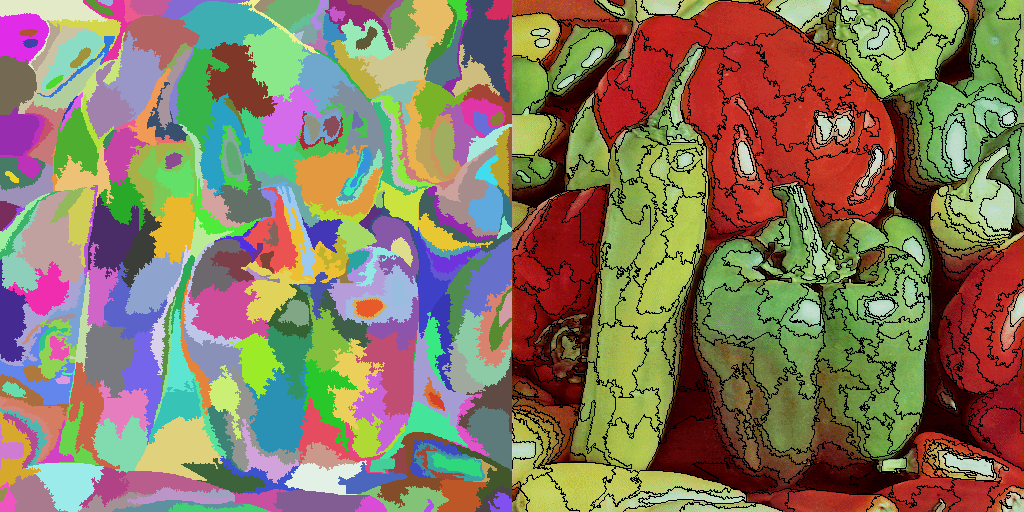

In [3]:
merged = segment(image, lattice=lattice, merge=MergeConfig(target_regions=300))
print(f"併合後: {merged.region_count}領域")
display(Image.fromarray(np.concatenate([
    render_labels(merged.labels), overlay_boundaries(image, merged.labels)
], axis=1)))

In [4]:
from permutohedral_segmentation import connected_components

assert raw.simplex_count == 16350
assert raw.component_count == 90755
assert merged.region_count == 300
assert np.unique(connected_components(merged.labels)).size == 300
print("領域数・連結性: 合格")

領域数・連結性: 合格


## 保存と再読込
画像の保存とラベルの読込は計算層とは別のAPIです。NPZには寸法と型が含まれます。
一時ディレクトリを使うため、このセルは既存の実験結果を書き換えません。

In [5]:
from pathlib import Path
from tempfile import TemporaryDirectory
from permutohedral_segmentation.io import save_result, load_result

with TemporaryDirectory() as temporary:
    destination = save_result(Path(temporary) / "roundtrip", image, merged)
    loaded_labels, metadata = load_result(destination)
    np.testing.assert_array_equal(loaded_labels, merged.labels)
print("NPZ/JSONの往復: 合格。保存時の領域数:", metadata["region_count"])

NPZ/JSONの往復: 合格。保存時の領域数: 300
